In [1]:
import json
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    confusion_matrix, roc_auc_score,
    f1_score, accuracy_score,
    mean_absolute_error
)
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

BASE       = '/content/drive/MyDrive/CDT_Dataset'
LABEL_PATH = f'{BASE}/labels/ccss_labels_v2.json'

import os
os.makedirs(f'{BASE}/results', exist_ok=True)

Mounted at /content/drive


In [2]:
test_df = pd.read_csv(
    f'{BASE}/labels/human_test.csv'
)
test_df['dementia_risk'] = (
    test_df['dementia_risk'].astype(bool)
)

with open(LABEL_PATH) as f:
    llm_labels = json.load(f)

print(f'Human test set: {len(test_df)} รูป')
print(f'  Normal  : {(~test_df["dementia_risk"]).sum()}')
print(f'  Dementia: {test_df["dementia_risk"].sum()}')
print(f'LLM labels  : {len(llm_labels)} รูป')

Human test set: 1328 รูป
  Normal  : 1103
  Dementia: 225
LLM labels  : 6602 รูป


In [5]:
DOMAINS = ['A', 'B', 'C', 'D', 'E']
DOMAIN_NAMES = {
    'A': 'digit_count',
    'B': 'worst_quadrant_error',
    'C': 'spatial_arrangement',
    'D': 'hands_present',
    'E': 'hands_placement'
}

rows      = []
not_found = []

for _, row in test_df.iterrows():
    filename_orig = row['filename'].replace(
        '.jpg', '.tif'
    )
    filename_jpg  = row['filename']

    llm = llm_labels.get(filename_orig) or \
          llm_labels.get(filename_jpg)

    if llm is None:
        not_found.append(row['filename'])
        continue

    llm_scores = llm.get('scores', {})

    entry = {
        'filename'     : row['filename'],
        'true_A'       : row['domain_A'],
        'true_B'       : row['domain_B'],
        'true_C'       : row['domain_C'],
        'true_D'       : row['domain_D'],
        'true_E'       : row['domain_E'],
        'true_total'   : row['total_score'],
        'true_dementia': int(row['dementia_risk']),
        'pred_A'       : llm_scores.get(
            'digit_count', 0),
        'pred_B'       : llm_scores.get(
            'worst_quadrant_error', 0),
        'pred_C'       : llm_scores.get(
            'spatial_arrangement', 0),
        'pred_D'       : llm_scores.get(
            'hands_present', 0),
        'pred_E'       : llm_scores.get(
            'hands_placement', 0),
        'llm_confidence': llm.get('confidence', 0),
    }

    entry['pred_total']    = (
        entry['pred_A'] + entry['pred_B'] +
        entry['pred_C'] + entry['pred_D'] +
        entry['pred_E']
    )
    entry['pred_dementia'] = int(
        entry['pred_total'] < 6
    )

    rows.append(entry)

result_df = pd.DataFrame(rows)

print(f'จับคู่สำเร็จ: {len(result_df)} รูป')
print(f'ไม่พบใน LLM: {len(not_found)} รูป')

จับคู่สำเร็จ: 1328 รูป
ไม่พบใน LLM: 0 รูป


In [6]:
print('='*60)
print('Per-Domain Metrics (LLM vs Human Labels)')
print('='*60)
print(f'{"Domain":<25} {"Acc":>8} {"MAE":>8} {"F1":>8}')
print('-'*55)

domain_metrics = {}

for d in DOMAINS:
    true_vals = result_df[f'true_{d}'].values
    pred_vals = result_df[f'pred_{d}'].values

    acc = accuracy_score(true_vals, pred_vals)
    mae = mean_absolute_error(true_vals, pred_vals)
    f1  = f1_score(
        true_vals, pred_vals,
        average='macro', zero_division=0
    )

    domain_metrics[d] = {
        'accuracy': acc, 'mae': mae, 'f1': f1
    }

    name = DOMAIN_NAMES[d]
    print(f'{name:<25} {acc:>8.3f} '
          f'{mae:>8.3f} {f1:>8.3f}')

avg_acc = np.mean(
    [m['accuracy'] for m in domain_metrics.values()]
)
avg_mae = np.mean(
    [m['mae'] for m in domain_metrics.values()]
)

print('-'*55)
print(f'{"Average":<25} {avg_acc:>8.3f} '
      f'{avg_mae:>8.3f}')
print('='*60)

Per-Domain Metrics (LLM vs Human Labels)
Domain                         Acc      MAE       F1
-------------------------------------------------------
digit_count                  0.906    0.119    0.710
worst_quadrant_error         0.795    0.230    0.775
spatial_arrangement          0.877    0.166    0.706
hands_present                0.605    0.447    0.470
hands_placement              0.788    0.317    0.574
-------------------------------------------------------
Average                      0.794    0.256


In [7]:
true_dementia = result_df['true_dementia'].values
pred_total    = result_df['pred_total'].values

print('='*55)
print('LLM Baseline vs Human Ground Truth')
print('='*55)
print(f'{"Cutoff":>8} {"Sens":>8} '
      f'{"Spec":>8} {"AUC":>8}')
print('-'*40)

best_cutoff = None
best_score  = -1

for cutoff in [5, 6, 7, 8]:
    pred_dem = (pred_total < cutoff).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(
            true_dementia, pred_dem, labels=[0,1]
        ).ravel()
        sens = tp/(tp+fn) if (tp+fn) > 0 else 0
        spec = tn/(tn+fp) if (tn+fp) > 0 else 0
        auc  = roc_auc_score(
            true_dementia, -pred_total
        )
    except:
        sens, spec, auc = 0, 0, 0

    # mark = '✅' if (sens >= 0.88 and
    #                spec >= 0.82) else '⚠️'
    print(f'{cutoff:>8} {sens:>8.3f} '
          f'{spec:>8.3f} {auc:>8.3f}')

    if sens + spec > best_score:
        best_score  = sens + spec
        best_cutoff = cutoff
        best_sens   = sens
        best_spec   = spec
        best_auc    = auc

print(f'\nBest cutoff = {best_cutoff}')
print(f'  Sens={best_sens:.3f} '
      f'Spec={best_spec:.3f} '
      f'AUC={best_auc:.3f}')

LLM Baseline vs Human Ground Truth
  Cutoff     Sens     Spec      AUC
----------------------------------------
       5    0.449    0.983    0.873
       6    0.600    0.967    0.873
       7    0.684    0.937    0.873
       8    0.711    0.925    0.873

Best cutoff = 8
  Sens=0.711 Spec=0.925 AUC=0.873


In [8]:
llm_old = {
    'cutoff_6': {'sens': 0.731, 'spec': 0.975,
                 'auc' : 0.944},
    'cutoff_7': {'sens': 0.909, 'spec': 0.958,
                 'auc' : 0.944},
}

print('='*70)
print('เปรียบ LLM Baseline: LLM Test vs Human Test')
print('='*70)
print(f'{"":20} {"LLM Test (เดิม)":>20} '
      f'{"Human Test (ใหม่)":>20}')
print(f'{"Cutoff":20} {"Sens/Spec/AUC":>20} '
      f'{"Sens/Spec/AUC":>20}')
print('='*70)

for cutoff in [6, 7]:
    old = llm_old[f'cutoff_{cutoff}']
    pred_dem = (pred_total < cutoff).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(
            true_dementia, pred_dem, labels=[0,1]
        ).ravel()
        new_sens = tp/(tp+fn) if (tp+fn) > 0 else 0
        new_spec = tn/(tn+fp) if (tn+fp) > 0 else 0
        new_auc  = roc_auc_score(
            true_dementia, -pred_total
        )
    except:
        new_sens, new_spec, new_auc = 0, 0, 0

    old_str = (f'{old["sens"]:.3f}/'
               f'{old["spec"]:.3f}/'
               f'{old["auc"]:.3f}')
    new_str = (f'{new_sens:.3f}/'
               f'{new_spec:.3f}/'
               f'{new_auc:.3f}')

    print(f'Cutoff {cutoff:<14} {old_str:>20} '
          f'{new_str:>20}')

print('='*70)

เปรียบ LLM Baseline: LLM Test vs Human Test
                          LLM Test (เดิม)    Human Test (ใหม่)
Cutoff                      Sens/Spec/AUC        Sens/Spec/AUC
Cutoff 6                 0.731/0.975/0.944    0.600/0.967/0.873
Cutoff 7                 0.909/0.958/0.944    0.684/0.937/0.873


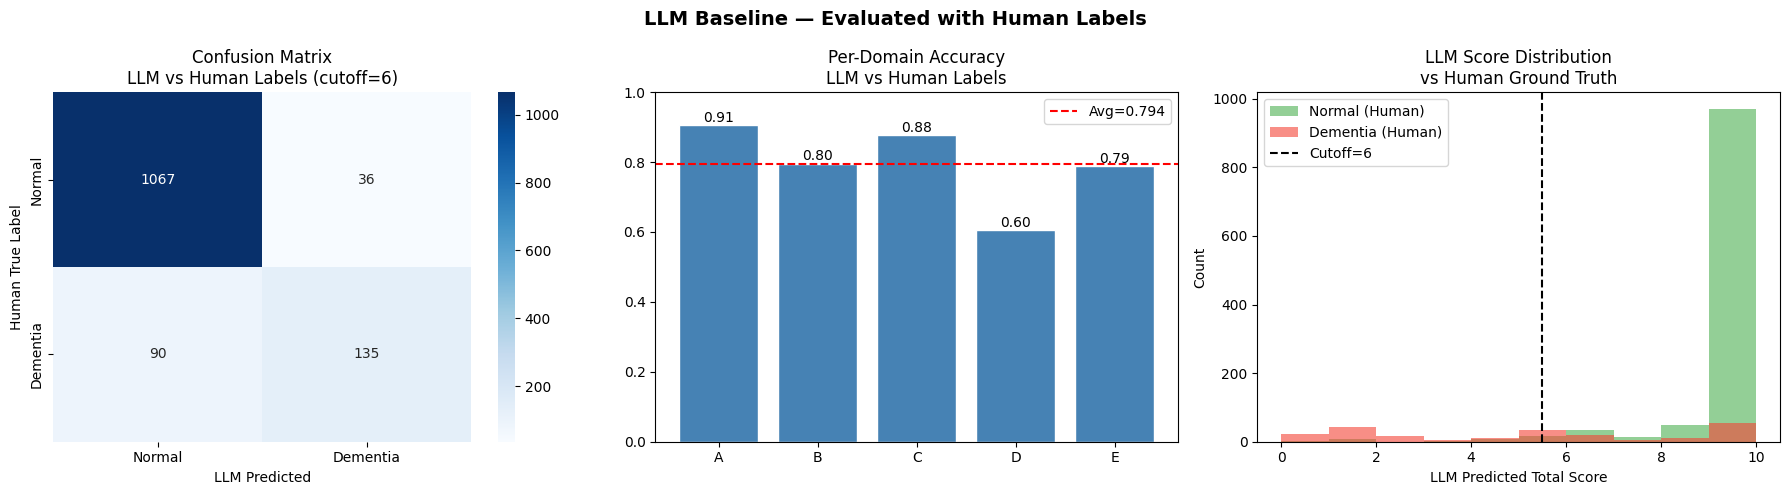

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# กราฟ 1: Confusion Matrix (cutoff=6)
pred_dem6 = (pred_total < 6).astype(int)
cm = confusion_matrix(true_dementia, pred_dem6)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    ax=axes[0],
    xticklabels=['Normal', 'Dementia'],
    yticklabels=['Normal', 'Dementia']
)
axes[0].set_title(
    'Confusion Matrix\nLLM vs Human Labels (cutoff=6)'
)
axes[0].set_xlabel('LLM Predicted')
axes[0].set_ylabel('Human True Label')

# กราฟ 2: Per-domain Accuracy
domain_accs = [
    domain_metrics[d]['accuracy'] for d in DOMAINS
]
bars = axes[1].bar(
    DOMAINS, domain_accs,
    color='steelblue', edgecolor='white'
)
axes[1].axhline(
    y=np.mean(domain_accs),
    color='red', linestyle='--',
    label=f'Avg={np.mean(domain_accs):.3f}'
)
axes[1].set_title(
    'Per-Domain Accuracy\nLLM vs Human Labels'
)
axes[1].set_ylim(0, 1)
axes[1].legend()
for bar, val in zip(bars, domain_accs):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{val:.2f}', ha='center', fontsize=10
    )

# กราฟ 3: Score Distribution
axes[2].hist(
    result_df[
        result_df['true_dementia']==0
    ]['pred_total'],
    bins=10, alpha=0.6,
    color='#4CAF50', label='Normal (Human)'
)
axes[2].hist(
    result_df[
        result_df['true_dementia']==1
    ]['pred_total'],
    bins=10, alpha=0.6,
    color='#F44336', label='Dementia (Human)'
)
axes[2].axvline(
    x=5.5, color='black',
    linestyle='--', label='Cutoff=6'
)
axes[2].set_title(
    'LLM Score Distribution\nvs Human Ground Truth'
)
axes[2].set_xlabel('LLM Predicted Total Score')
axes[2].set_ylabel('Count')
axes[2].legend()

plt.suptitle(
    'LLM Baseline — Evaluated with Human Labels',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.savefig(
    f'{BASE}/results/baseline_llm_human.png',
    dpi=150, bbox_inches='tight'
)
plt.show()

In [10]:
baseline_human = {
    'model'             : 'LLM Baseline (Human Test)',
    'test_set'          : 'human_test.csv',
    'n_samples'         : len(result_df),
    'best_cutoff'       : best_cutoff,
    'sensitivity'       : round(float(best_sens), 4),
    'specificity'       : round(float(best_spec), 4),
    'auc_roc'           : round(float(best_auc), 4),
    'avg_domain_accuracy': round(float(avg_acc), 4),
    'avg_domain_mae'    : round(float(avg_mae), 4),
    'per_domain'        : {
        d: {k: round(v, 4)
            for k, v in m.items()}
        for d, m in domain_metrics.items()
    },
    'note': (
        'Evaluated with human ground truth labels. '
        'More reliable than LLM self-evaluation.'
    )
}

with open(
    f'{BASE}/results/baseline_llm_human.json', 'w'
) as f:
    json.dump(baseline_human, f, indent=2)

print(f'\nสรุป LLM Baseline (Human Test):')
print(f'  Best cutoff : {best_cutoff}')
print(f'  Sensitivity : {best_sens:.3f}')
print(f'  Specificity : {best_spec:.3f}')
print(f'  AUC-ROC     : {best_auc:.3f} ')
print(f'\nเปรียบกับ LLM baseline เดิม (LLM test):')
print(f'  Sens: 0.909 → {best_sens:.3f}')
print(f'  Spec: 0.958 → {best_spec:.3f}')
print(f'  AUC : 0.944 → {best_auc:.3f}')


สรุป LLM Baseline (Human Test):
  Best cutoff : 8
  Sensitivity : 0.711
  Specificity : 0.925
  AUC-ROC     : 0.873 

เปรียบกับ LLM baseline เดิม (LLM test):
  Sens: 0.909 → 0.711
  Spec: 0.958 → 0.925
  AUC : 0.944 → 0.873


In [11]:
baseline_human['cutoff_results'] = {}
for cutoff in [5, 6, 7, 8]:
    pred_dem = (pred_total < cutoff).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(
            true_dementia, pred_dem, labels=[0,1]
        ).ravel()
        sens = tp/(tp+fn) if (tp+fn) > 0 else 0
        spec = tn/(tn+fp) if (tn+fp) > 0 else 0
    except:
        sens, spec = 0, 0
    baseline_human['cutoff_results'][str(cutoff)] = {
        'sensitivity': round(float(sens), 4),
        'specificity': round(float(spec), 4),
    }

with open(
    f'{BASE}/results/baseline_llm_human.json', 'w'
) as f:
    json.dump(baseline_human, f, indent=2)